In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, cohen_kappa_score,
    matthews_corrcoef, confusion_matrix, classification_report
)
from sklearn.inspection import permutation_importance
import shap

sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams['font.sans-serif'] = 'Arial'
print("Machine learning, tuning, and interpretability libraries successfully imported.")

Machine learning, tuning, and interpretability libraries successfully imported.


In [2]:
csv_path = "womens_clothing_classification_dataset.csv"
if not os.path.exists(csv_path):
    csv_path = os.path.join("26-10-2026", "Task 1", "womens_clothing_classification_dataset.csv")

df = pd.read_csv(csv_path)
print(f"Dataset Loaded: {df.shape[0]} customer reviews across {df.shape[1]} features.")

num_features = [
    'Age',
    'Rating',
    'Positive Feedback Count',
    'Review_Length',
    'Review_Word_Count',
    'Exclamation_Count',
    'Sentiment_Compound',
    'Sentiment_Pos',
    'Sentiment_Neg',
    'Positive_Word_Count',
    'Negative_Word_Count',
    'Fit_Issue_Word_Count',
    'Rating_x_Sentiment'
]
cat_features = ['Department Name', 'Division Name']
target = 'Recommended IND'

X = df[num_features + cat_features]
y = df[target]

# Stratified 80/20 train-test split to preserve class imbalance
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), cat_features)
    ]
)

X_train_trans = preprocessor.fit_transform(X_train)
X_test_trans = preprocessor.transform(X_test)

cat_cols = list(preprocessor.named_transformers_['cat'].get_feature_names_out(cat_features))
all_feature_names = num_features + cat_cols

print(f"Training set: {X_train_trans.shape[0]} rows | Test set: {X_test_trans.shape[0]} rows")
print(f"Engineered feature dimensionality: {len(all_feature_names)} features.")
print(f"Class Distribution: {np.mean(y_train == 1)*100:.1f}% Recommended vs {np.mean(y_train == 0)*100:.1f}% Not Recommended.")

Dataset Loaded: 23486 customer reviews across 23 features.
Training set: 18788 rows | Test set: 4698 rows
Engineered feature dimensionality: 20 features.
Class Distribution: 82.2% Recommended vs 17.8% Not Recommended.


In [3]:
print("Fitting Baseline Models...")
rf_base = RandomForestClassifier(random_state=42, n_jobs=-1)
t0 = time.time()
rf_base.fit(X_train_trans, y_train)
rf_base_time = time.time() - t0

lr_base = LogisticRegression(max_iter=1000, random_state=42)
t0 = time.time()
lr_base.fit(X_train_trans, y_train)
lr_base_time = time.time() - t0

print(f"Baseline Random Forest trained in {rf_base_time:.2f} seconds.")
print(f"Baseline Logistic Regression trained in {lr_base_time:.2f} seconds.")

Fitting Baseline Models...
Baseline Random Forest trained in 0.71 seconds.
Baseline Logistic Regression trained in 0.04 seconds.


In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rf_param_dist = {
    'n_estimators': [100, 150, 200, 250],
    'max_depth': [8, 12, 16, 20, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2', 0.5],
    'class_weight': [None, 'balanced', 'balanced_subsample']
}

print("Running RandomizedSearchCV for Random Forest (15 iterations x 5 folds = 75 fits)...")
rf_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=42, n_jobs=-1),
    param_distributions=rf_param_dist,
    n_iter=15,
    scoring='f1_macro',
    cv=cv,
    random_state=42,
    n_jobs=-1
)
rf_search.fit(X_train_trans, y_train)
best_rf = rf_search.best_estimator_
print("Best Random Forest Hyperparameters:", rf_search.best_params_)
print(f"Best CV Macro F1: {rf_search.best_score_:.4f}")

lr_param_dist = {
    'C': stats.loguniform(1e-3, 1e2),
    'penalty': ['l1', 'l2'],
    'solver': ['liblinear', 'saga'],
    'class_weight': [None, 'balanced']
}

print("\nRunning RandomizedSearchCV for Logistic Regression (15 iterations x 5 folds = 75 fits)...")
lr_search = RandomizedSearchCV(
    estimator=LogisticRegression(max_iter=1000, random_state=42),
    param_distributions=lr_param_dist,
    n_iter=15,
    scoring='f1_macro',
    cv=cv,
    random_state=42,
    n_jobs=-1
)
lr_search.fit(X_train_trans, y_train)
best_lr = lr_search.best_estimator_
print("Best Logistic Regression Hyperparameters:", lr_search.best_params_)
print(f"Best CV Macro F1: {lr_search.best_score_:.4f}")

Running RandomizedSearchCV for Random Forest (15 iterations x 5 folds = 75 fits)...
Best Random Forest Hyperparameters: {'n_estimators': 250, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 0.5, 'max_depth': 8, 'class_weight': None}
Best CV Macro F1: 0.9022

Running RandomizedSearchCV for Logistic Regression (15 iterations x 5 folds = 75 fits)...


C:\Users\panch\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Best Logistic Regression Hyperparameters: {'C': np.float64(49.29053648241677), 'class_weight': 'balanced', 'penalty': 'l2', 'solver': 'saga'}
Best CV Macro F1: 0.9002


In [5]:
models = {
    'Baseline Random Forest': rf_base,
    'Tuned Random Forest': best_rf,
    'Baseline Logistic Regression': lr_base,
    'Tuned Logistic Regression': best_lr
}

metrics_list = []
for name, model in models.items():
    y_pred = model.predict(X_test_trans)
    y_prob = model.predict_proba(X_test_trans)[:, 1]
    
    metrics_list.append({
        'Model': name,
        'Accuracy': round(accuracy_score(y_test, y_pred), 4),
        'Recall_Class0 (Dissatisfied)': round(recall_score(y_test, y_pred, pos_label=0), 4),
        'Precision_Class0': round(precision_score(y_test, y_pred, pos_label=0), 4),
        'Recall_Class1 (Recommended)': round(recall_score(y_test, y_pred, pos_label=1), 4),
        'Macro_F1': round(f1_score(y_test, y_pred, average='macro'), 4),
        'ROC_AUC': round(roc_auc_score(y_test, y_prob), 4),
        'PR_AUC': round(average_precision_score(y_test, y_prob), 4),
        'Cohen_Kappa': round(cohen_kappa_score(y_test, y_pred), 4),
        'MCC': round(matthews_corrcoef(y_test, y_pred), 4)
    })

df_metrics = pd.DataFrame(metrics_list)
df_metrics.to_csv("model_comparison_rf_vs_lr.csv", index=False)
print("Model Comparison on Test Set:")
df_metrics

Model Comparison on Test Set:


,Model,Accuracy,Recall_Class0 (Dissatisfied),Precision_Class0,Recall_Class1 (Recommended),Macro_F1,ROC_AUC,PR_AUC,Cohen_Kappa,MCC
0,Baseline Random Forest,0.9395,0.8419,0.8222,0.9607,0.8975,0.9687,0.9903,0.7951,0.7952
1,Tuned Random Forest,0.9413,0.8503,0.8246,0.9609,0.9007,0.9753,0.9939,0.8014,0.8016
2,Baseline Logistic Regression,0.9430,0.8228,0.8513,0.9689,0.9011,0.9778,0.9948,0.8022,0.8024
3,Tuned Logistic Regression,0.9355,0.9473,0.7533,0.9330,0.8995,0.9779,0.9948,0.7996,0.8078


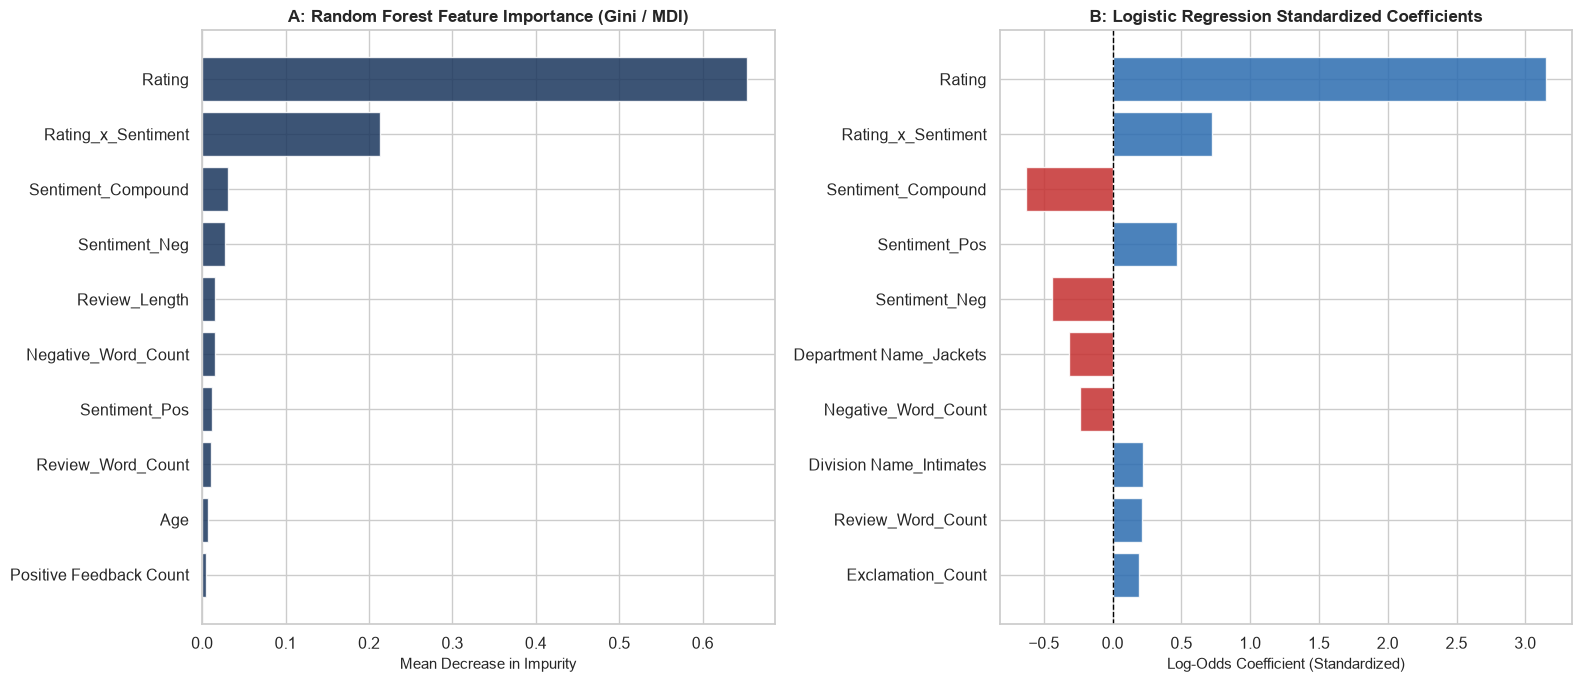

In [6]:
rf_mdi = best_rf.feature_importances_
perm_res = permutation_importance(best_rf, X_test_trans, y_test, n_repeats=5, random_state=42, n_jobs=-1)
rf_perm = perm_res.importances_mean
lr_coef = best_lr.coef_[0]

df_importance = pd.DataFrame({
    'Feature': all_feature_names,
    'RF_Gini_Importance': rf_mdi,
    'RF_Permutation_Importance': rf_perm,
    'LR_Coefficient': lr_coef,
    'LR_Abs_Coefficient': np.abs(lr_coef)
}).sort_values(by='RF_Gini_Importance', ascending=False)

df_importance.to_csv("feature_importance_rankings.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

top_rf = df_importance.sort_values(by='RF_Gini_Importance', ascending=True).tail(10)
axes[0].barh(top_rf['Feature'], top_rf['RF_Gini_Importance'], color='#1A365D', alpha=0.85)
axes[0].set_title("A: Random Forest Feature Importance (Gini / MDI)", fontweight='bold', fontsize=12)
axes[0].set_xlabel("Mean Decrease in Impurity", fontsize=11)

top_lr = df_importance.sort_values(by='LR_Abs_Coefficient', ascending=True).tail(10)
colors = ['#2B6CB0' if c > 0 else '#C53030' for c in top_lr['LR_Coefficient']]
axes[1].barh(top_lr['Feature'], top_lr['LR_Coefficient'], color=colors, alpha=0.85)
axes[1].axvline(0, color='black', linestyle='--', linewidth=1)
axes[1].set_title("B: Logistic Regression Standardized Coefficients", fontweight='bold', fontsize=12)
axes[1].set_xlabel("Log-Odds Coefficient (Standardized)", fontsize=11)

plt.tight_layout()
plt.savefig("feature_importance_comparison.png", dpi=300)
plt.show()

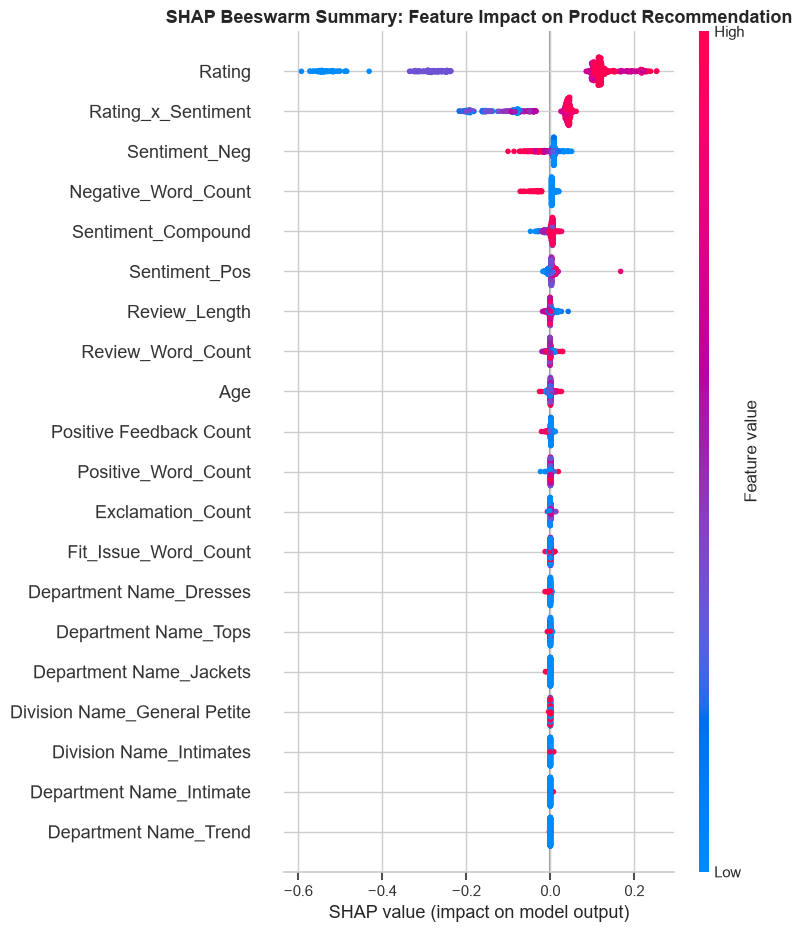

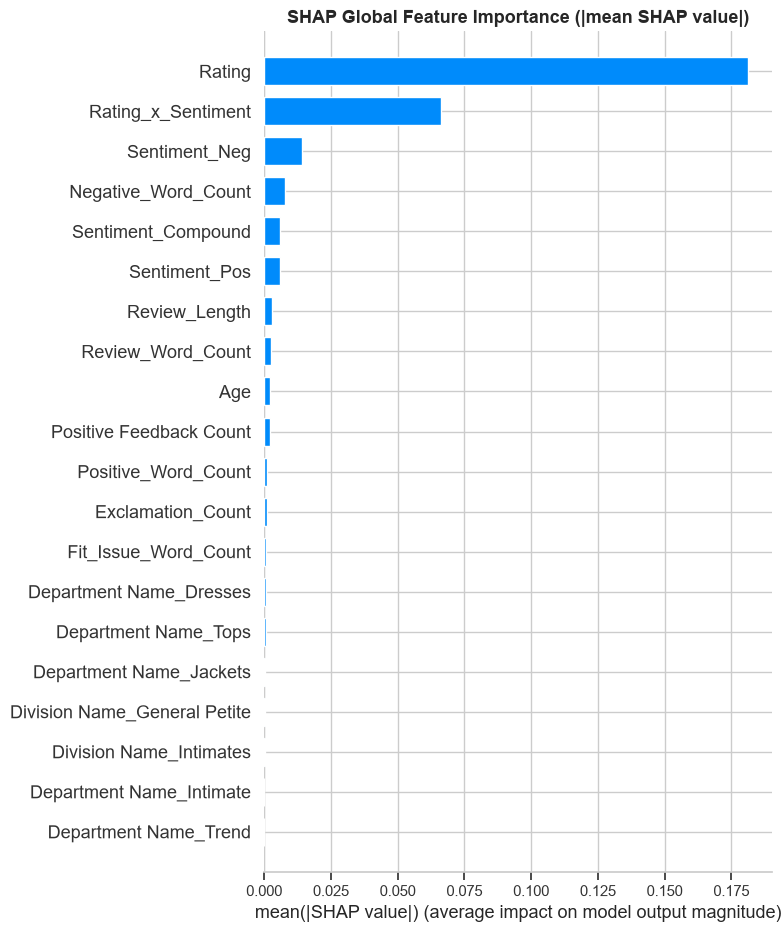

In [7]:
sample_size = 500
X_sample = X_test_trans[:sample_size]
X_sample_df = pd.DataFrame(X_sample, columns=all_feature_names)

explainer = shap.TreeExplainer(best_rf)
shap_values = explainer.shap_values(X_sample)

if isinstance(shap_values, list):
    shap_vals_class1 = shap_values[1]
elif len(shap_values.shape) == 3:
    shap_vals_class1 = shap_values[:, :, 1]
else:
    shap_vals_class1 = shap_values

plt.figure(figsize=(11, 7))
shap.summary_plot(shap_vals_class1, X_sample_df, show=False)
plt.title("SHAP Beeswarm Summary: Feature Impact on Product Recommendation", fontweight='bold', fontsize=13)
plt.tight_layout()
plt.savefig("shap_summary_beeswarm.png", dpi=300, bbox_inches='tight')
plt.show()

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_vals_class1, X_sample_df, plot_type="bar", show=False)
plt.title("SHAP Global Feature Importance (|mean SHAP value|)", fontweight='bold', fontsize=13)
plt.tight_layout()
plt.savefig("shap_feature_importance_bar.png", dpi=300, bbox_inches='tight')
plt.show()

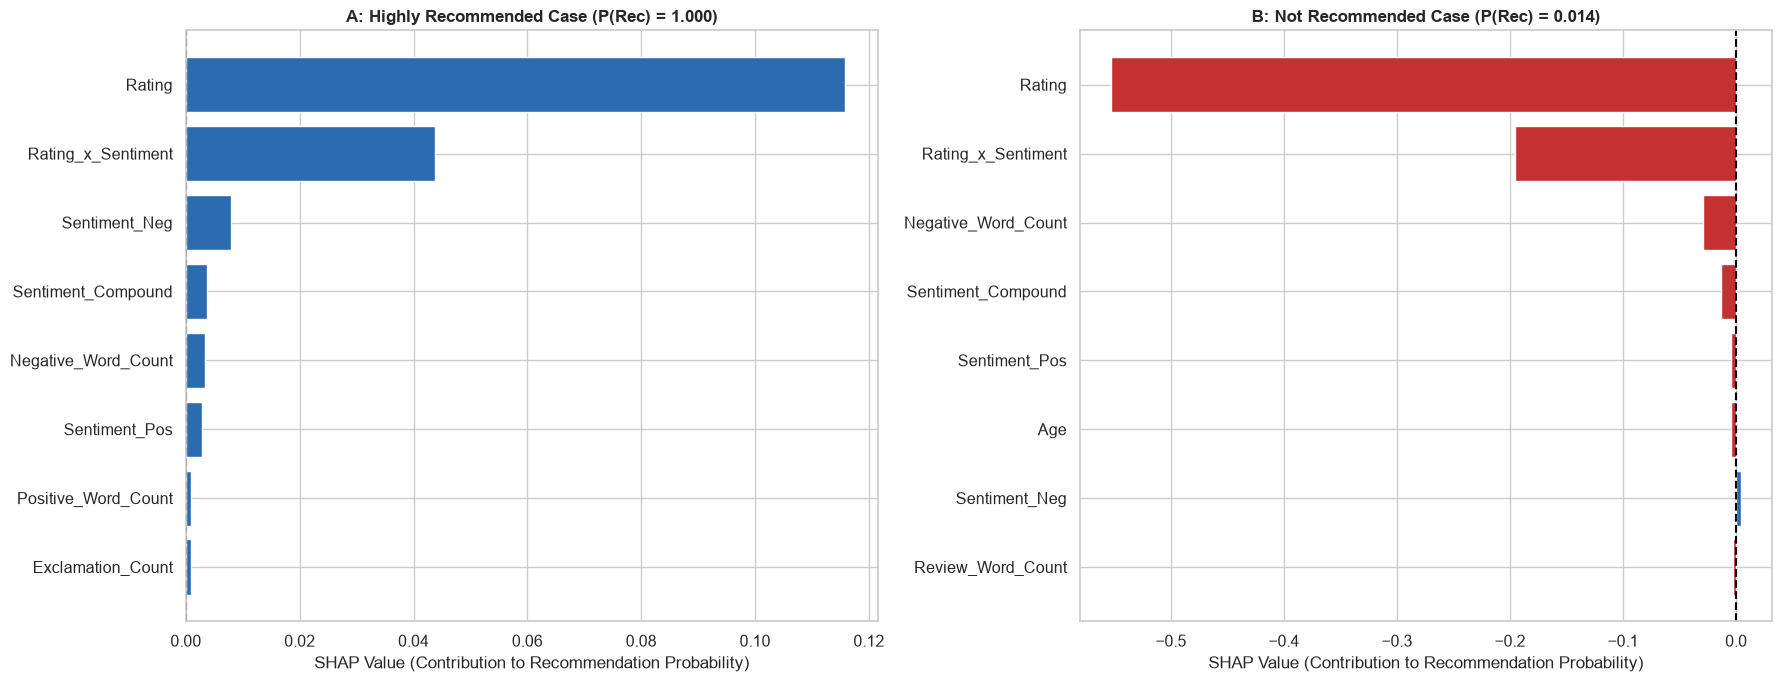

In [8]:
probs = best_rf.predict_proba(X_sample)[:, 1]
idx_high = int(np.argmax(probs))
idx_low = int(np.argmin(probs))

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
sorted_idx_h = np.argsort(np.abs(shap_vals_class1[idx_high]))[-8:]
axes[0].barh(
    [all_feature_names[i] for i in sorted_idx_h],
    shap_vals_class1[idx_high][sorted_idx_h],
    color=['#2B6CB0' if v > 0 else '#C53030' for v in shap_vals_class1[idx_high][sorted_idx_h]]
)
axes[0].axvline(0, color='black', linestyle='--')
axes[0].set_title(f"A: Highly Recommended Case (P(Rec) = {probs[idx_high]:.3f})", fontweight='bold', fontsize=12)
axes[0].set_xlabel("SHAP Value (Contribution to Recommendation Probability)")

sorted_idx_l = np.argsort(np.abs(shap_vals_class1[idx_low]))[-8:]
axes[1].barh(
    [all_feature_names[i] for i in sorted_idx_l],
    shap_vals_class1[idx_low][sorted_idx_l],
    color=['#2B6CB0' if v > 0 else '#C53030' for v in shap_vals_class1[idx_low][sorted_idx_l]]
)
axes[1].axvline(0, color='black', linestyle='--')
axes[1].set_title(f"B: Not Recommended Case (P(Rec) = {probs[idx_low]:.3f})", fontweight='bold', fontsize=12)
axes[1].set_xlabel("SHAP Value (Contribution to Recommendation Probability)")

plt.tight_layout()
plt.savefig("shap_waterfall_examples.png", dpi=300)
plt.show()